In [2]:
import open3d as o3d
import numpy as np
import plotly.graph_objects as go
import potpourri3d as pp3d


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [3]:
#Visualize 
points = []

with open("bunny.obj") as f:
    for line in f:
        if line.startswith("v "):
            _, x, y, z = line.split()
            points.append([float(x), float(y), float(z)])

points = np.array(points)

fig = go.Figure(
    go.Scatter3d(
        x=points[:, 0],
        y=points[:, 1],
        z=points[:, 2],
        mode="markers",
        marker=dict(
            size=1.5,
            opacity=0.8,
        ),
    )
)

fig.update_layout(
    scene=dict(aspectmode="data"),
    margin=dict(l=0, r=0, b=0, t=0),
)

fig.show()

Local point-cloud estimation pipeline
======================================

    Point cloud
        |
        v
      kNN
        |
        v
Covariance Estimation + PCA   (Robust scatter matrix Sigma/Tyler's M-estimator)
        |
        v
    Ellipsoid fit                (eigendecomposition of Sigma)
        |
        v
Local frame (v1, v2, v3)    (axes 1, axes 2, normal)  (tangent axes + normal)
        |
        v
Project neighbors into (u, v, w)     <- 3D -> 2D + height
 
        |
        v
Obtain height h(u, v)         (interpolate scattered w onto the probe grid)
        |
        v
Fit Bezier patch               (Bernstein-basis least squares)

Run on 1000 randomly sampled query points from a synthetic point cloud.

Note : 
1) Compare the difference between covariances: Large geodesic distance between neighborhoods' scatter matrices signals a genuine surface discontinuity, small distance signals a coherent smooth region.


In [4]:
import numpy as np
from scipy.spatial import cKDTree
from scipy.interpolate import griddata
from scipy.special import comb
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import open3d as o3d

In [5]:

OBJ_PATH   = "bunny.obj"   # <-- path to your .obj file
N_POINTS   = 1000          # points to sample from the mesh surface
k= 30
mesh = o3d.io.read_triangle_mesh(OBJ_PATH)
vertices = np.asarray(mesh.vertices)
print(vertices.shape)


(2503, 3)


In [6]:
# 0. Point cloud / Load data 
def load_data(OBJ_PATH):
    assert len(mesh.vertices) > 0, f"Could not read any geometry from {OBJ_PATH}"
    mesh.compute_vertex_normals()
    pcd = mesh.sample_points_poisson_disk(number_of_points=N_POINTS)
    points = np.asarray(pcd.points)
    print(f"Loaded {OBJ_PATH}")
    print(f"Mesh: {len(mesh.vertices)} vertices, {len(mesh.triangles)} triangles")
    print(f"Sampled point cloud: {points.shape[0]} points")
    return pcd
   
points= load_data(OBJ_PATH)

Loaded bunny.obj
Mesh: 2503 vertices, 4968 triangles
Sampled point cloud: 1000 points


In [7]:
def load_data(obj_path, n_points=N_POINTS):
    mesh = o3d.io.read_triangle_mesh(obj_path)
    assert len(mesh.vertices) > 0, \
        f"Could not read geometry from {obj_path}"
    mesh.compute_vertex_normals()
    pcd = mesh.sample_points_poisson_disk(
        number_of_points=n_points
    )
    points = np.asarray(pcd.points)
    print(f"Loaded {obj_path}")
    print(f"Mesh vertices : {len(mesh.vertices)}")
    print(f"Triangles     : {len(mesh.triangles)}")
    print(f"Point cloud   : {len(points)}")
    return mesh, pcd, points

mesh, pcd, points = load_data(OBJ_PATH)

Loaded bunny.obj
Mesh vertices : 2503
Triangles     : 4968
Point cloud   : 1000


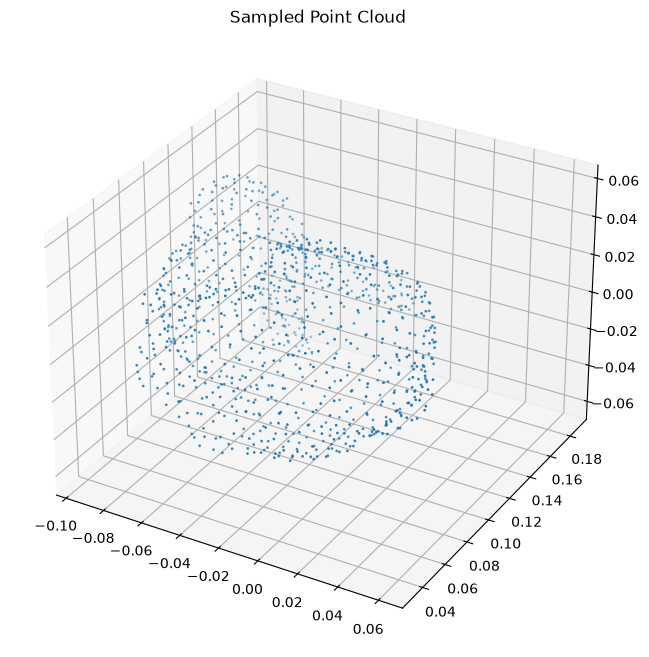

In [8]:
fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    points[:,0],
    points[:,1],
    points[:,2],
    s=1
)

ax.set_title("Sampled Point Cloud")
plt.show()

In [9]:
# 1. kNN



tree = cKDTree(points)
def knn(tree, p, k=30):
    _, idx = tree.query(p, k=k)
    return idx

num_samples = 20

random_indices = np.random.choice(
    len(points),
    size=num_samples,
    replace=False
)

query_points = points[random_indices]

print(query_points)


[[-0.05971029  0.04272266  0.04360056]
 [-0.01296069  0.12080653 -0.01132933]
 [-0.08623262  0.11400675  0.00273597]
 [-0.03857491  0.15866727 -0.01141558]
 [ 0.03168616  0.03881084  0.02497901]
 [-0.06200246  0.10021502  0.04223751]
 [-0.012359    0.12914725  0.00695743]
 [-0.04257596  0.04677676 -0.01171912]
 [-0.07345702  0.07657485  0.03573517]
 [ 0.00030404  0.08828913  0.05667592]
 [-0.05772005  0.04612853  0.02790934]
 [-0.06388012  0.11180872 -0.01341383]
 [-0.09199469  0.12492054  0.04122881]
 [-0.0518498   0.11066083  0.0373848 ]
 [-0.04941622  0.03986304 -0.01155457]
 [ 0.02630657  0.10829577 -0.0137366 ]
 [-0.01929276  0.03365625 -0.02352424]
 [ 0.02820904  0.07149868 -0.02246517]
 [-0.01110965  0.03862063  0.00047837]
 [-0.03217725  0.03395127  0.01450519]]


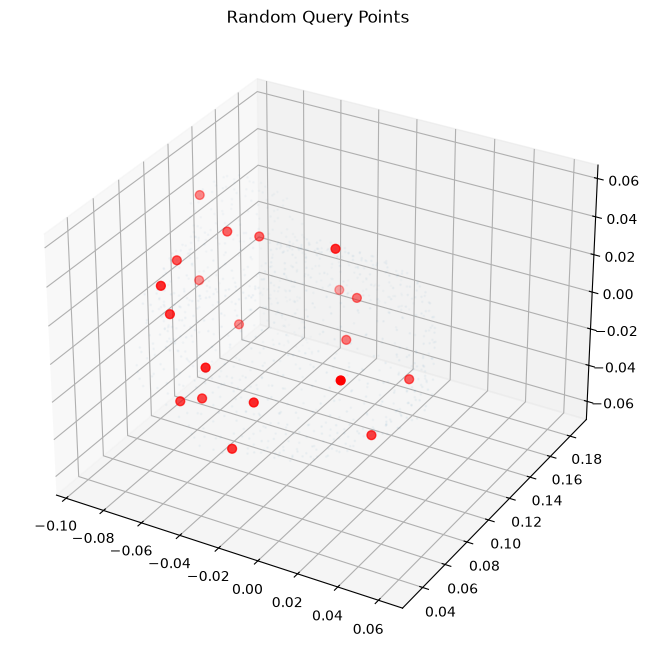

In [10]:
fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    points[:,0],
    points[:,1],
    points[:,2],
    s=1,
    alpha=.2
)

ax.scatter(
    query_points[:,0],
    query_points[:,1],
    query_points[:,2],
    color='red',
    s=40
)

ax.set_title("Random Query Points")
plt.show()

In [11]:
# 2. Compute Neighborhoods


k = 30

neighbor_indices = []

for p in query_points:
    idx = knn(tree, p, k)
    neighbor_indices.append(idx)

neighbor_indices = np.array(neighbor_indices)

print(neighbor_indices.shape)
print(neighbor_indices) 

(20, 30)
[[348 596 606  53 237 582 154 311 519 676 861 262 730 113 288 193 359 492
  448 851 912 119 360 183   3 496 510 845 786 155]
 [922 440 148 620 664 141 344 229 643 844 518 630 561 595 180 977 416 754
  828 134 939 222 848 989 918 452 153 552 418 571]
 [900 335 648 105 481 774 607 198 512 138 817 644 636 551 385 284 265 136
  681 182 979 430 881 660 837 459 315 101 706 331]
 [434 164  62 429 296 930 600  96 638   9 651 892 333 857 267 670 526 169
  529 646 699 149 488 827 781 889 191 372 757 716]
 [517 523 945 960 240 111 743  31 976  61 677 336 252 170 261 807 301 305
  665   2 291 999 813 875 725 995 285 652 826 120]
 [397 975 236 100  76 353 216 302 364 339 951 796 981 799 147 965 791 505
   57 228 690 270 165 768 441 398 128 815 739 790]
 [848 377 844 561 131 946 873 664 215 416 977 637 207 590 255 440 602 344
  701 940  58 630 777 922 307 249 918 562 895  52]
 [427 472 688 854  25 698 662 674 106 507 748 645   4  81 318 639 955 531
  227  28 151 445 876 631  68 565 497 809 

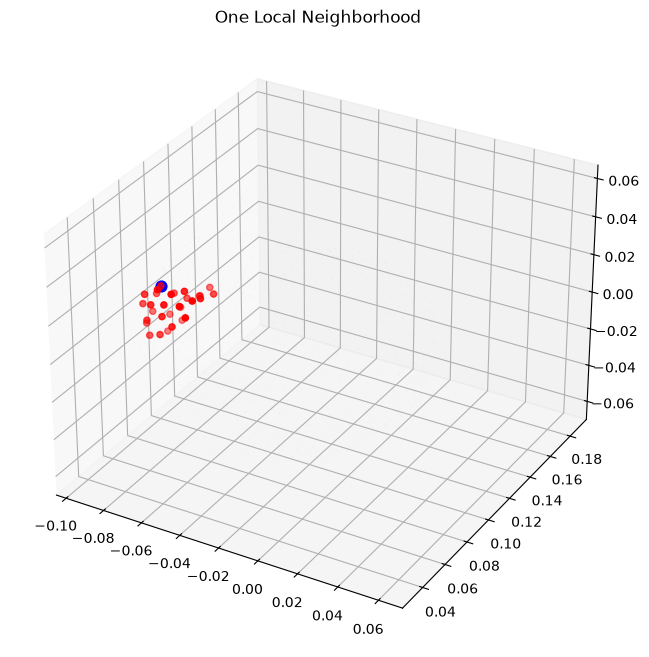

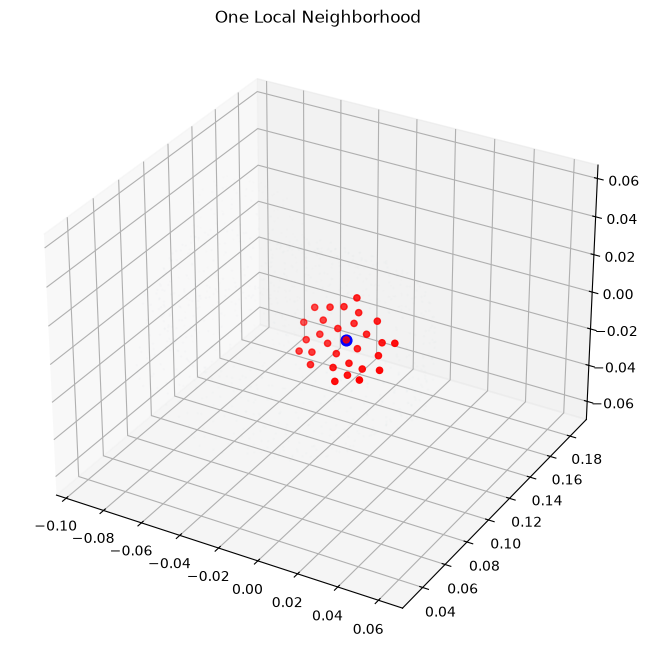

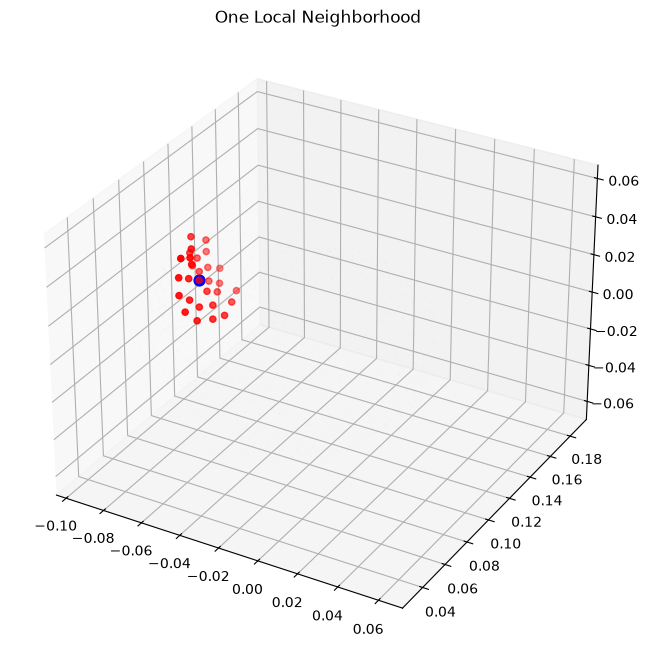

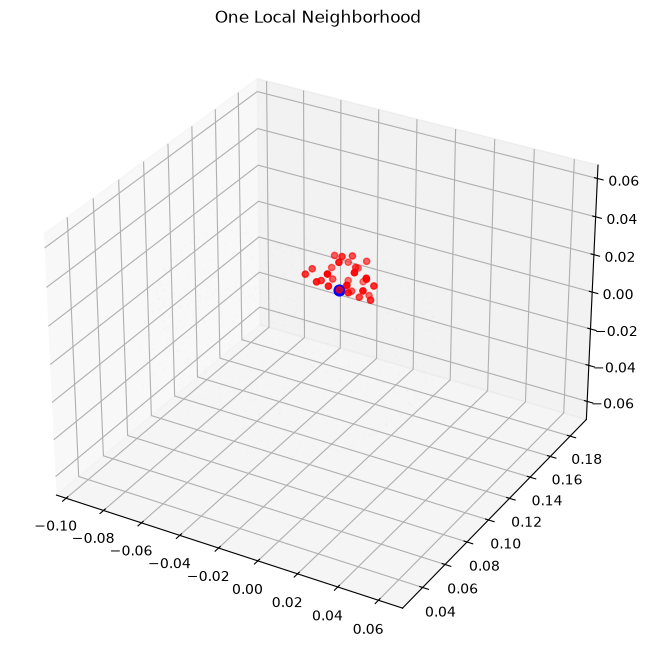

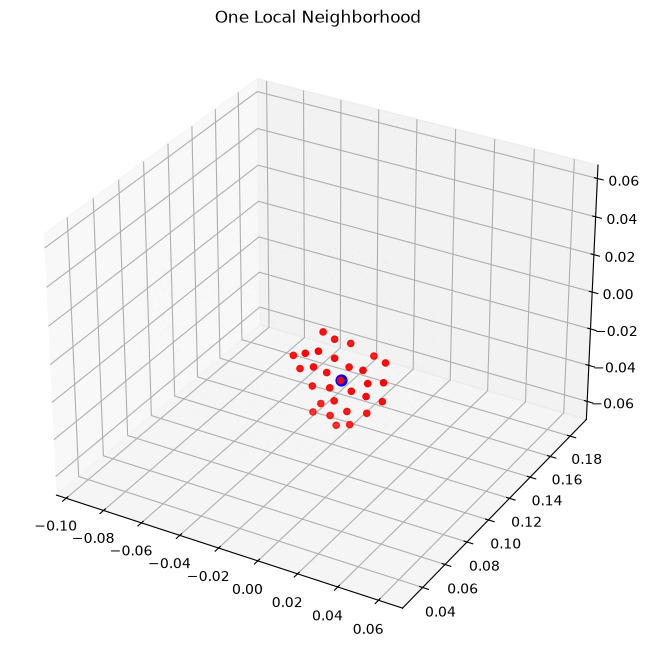

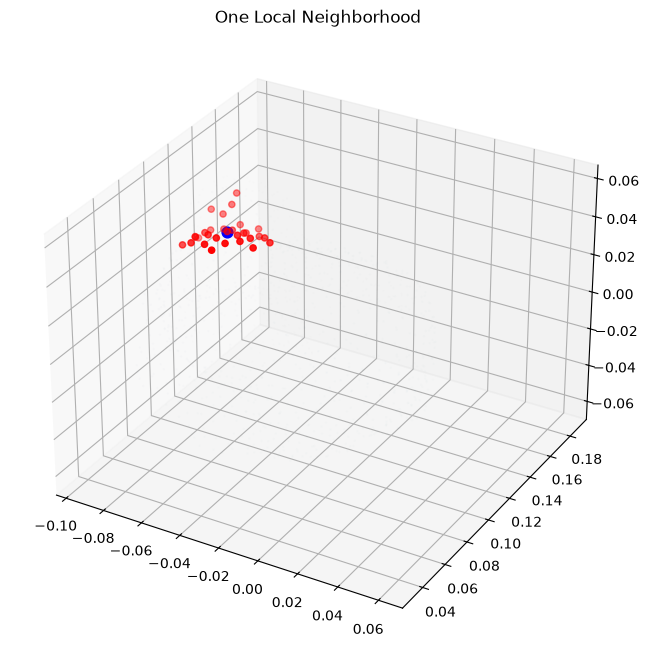

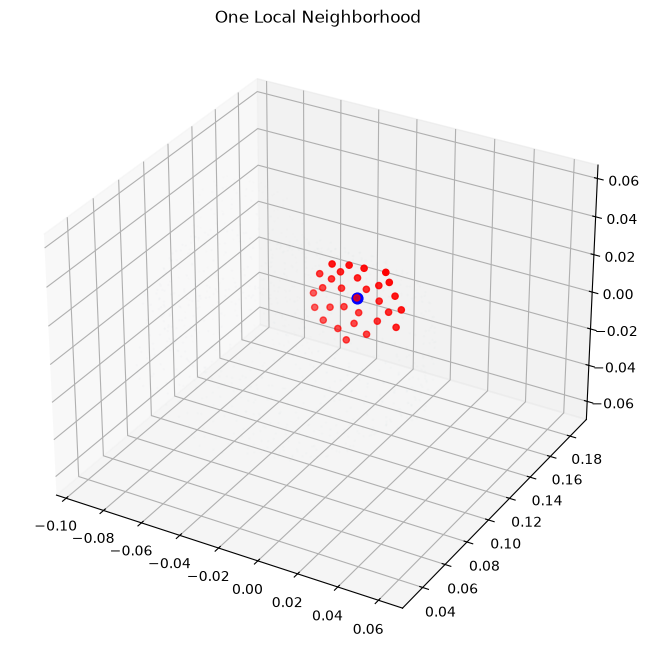

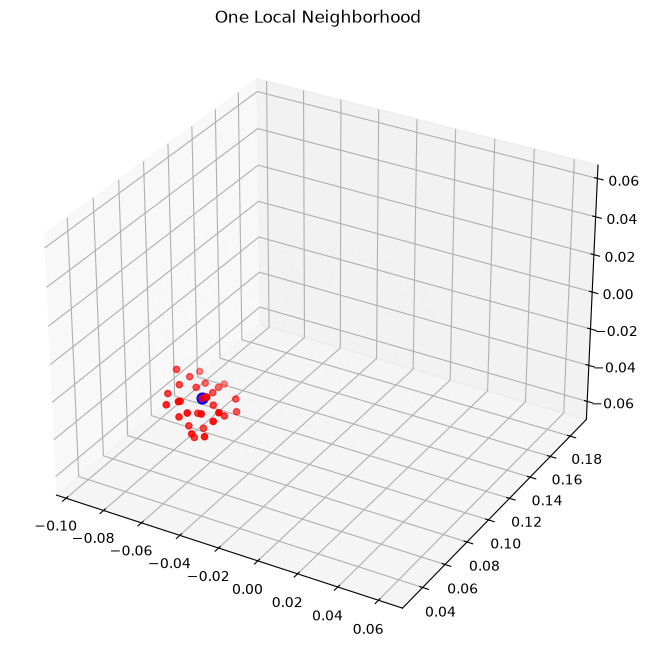

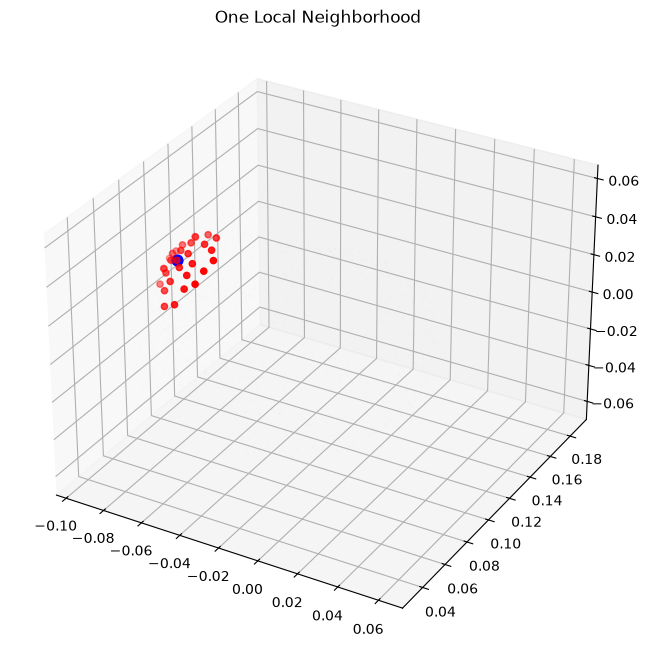

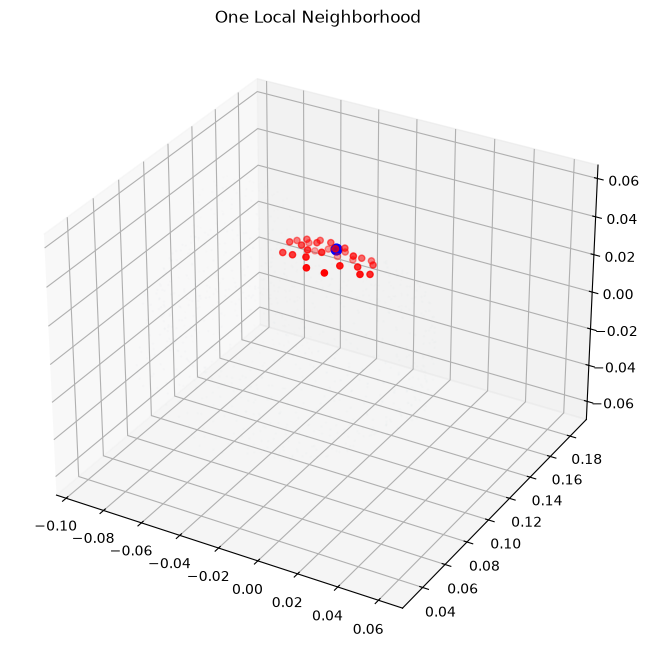

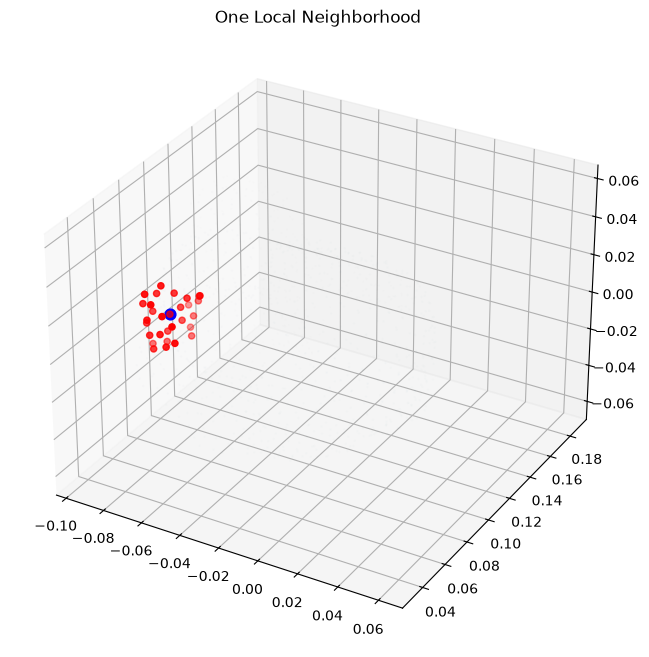

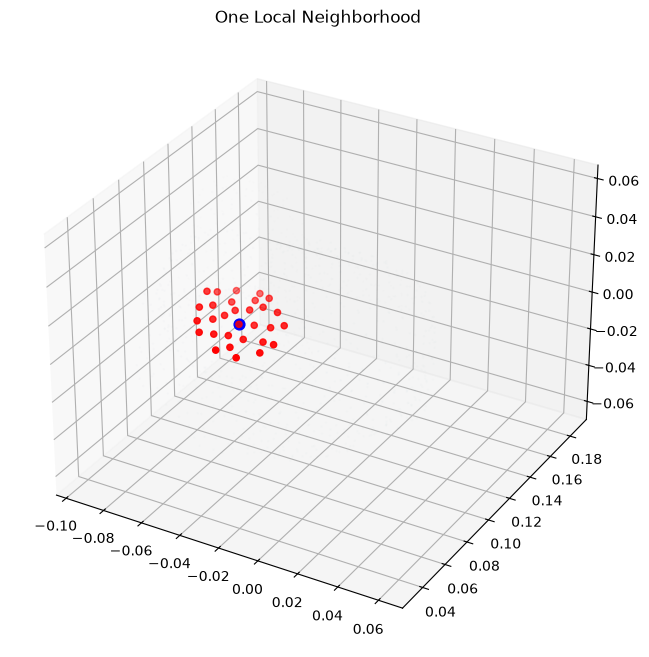

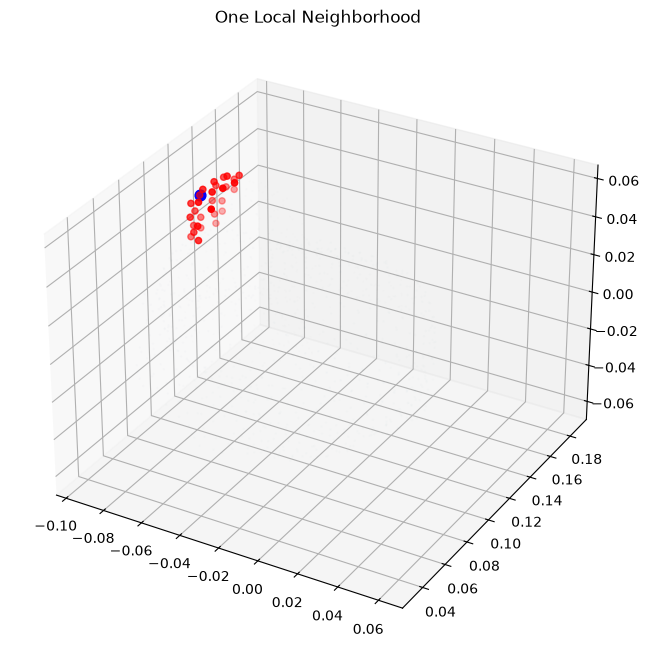

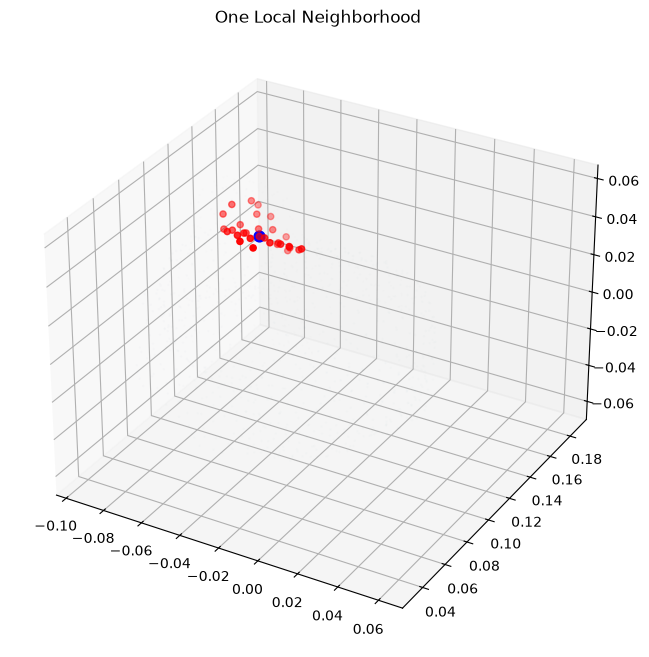

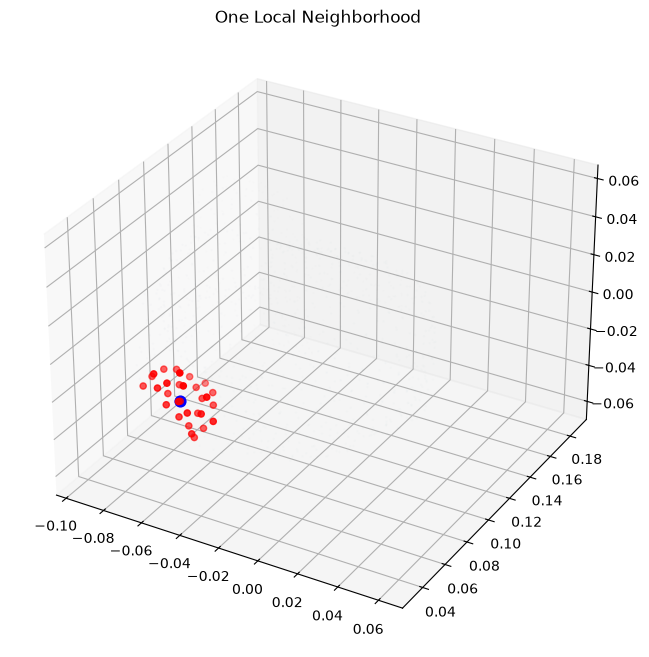

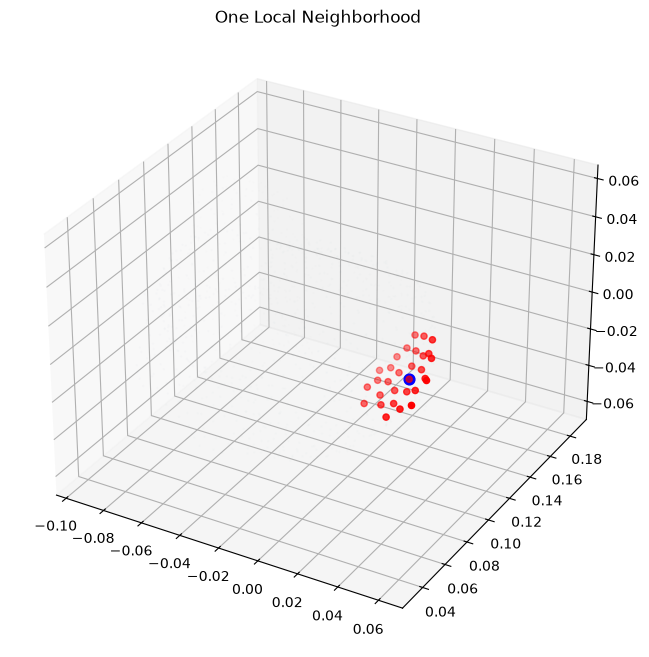

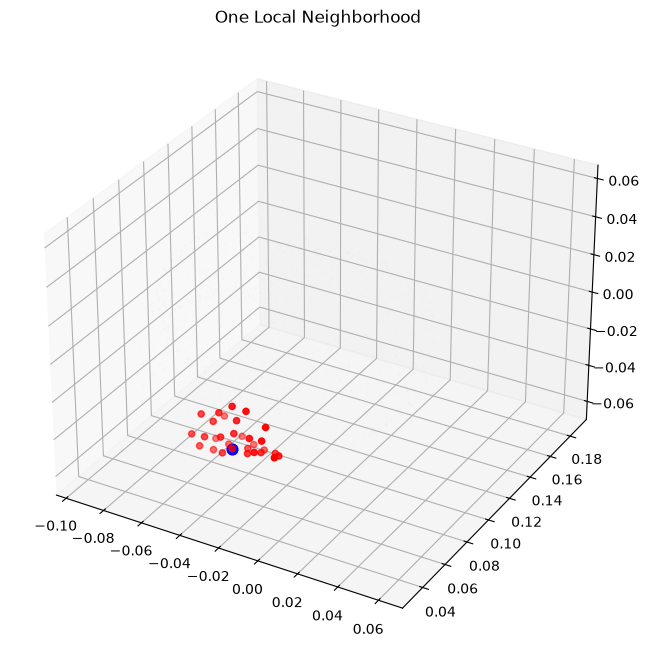

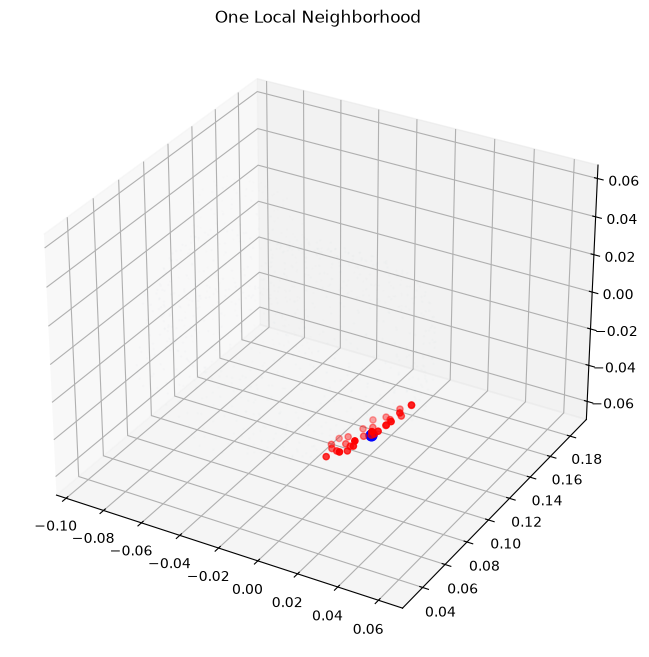

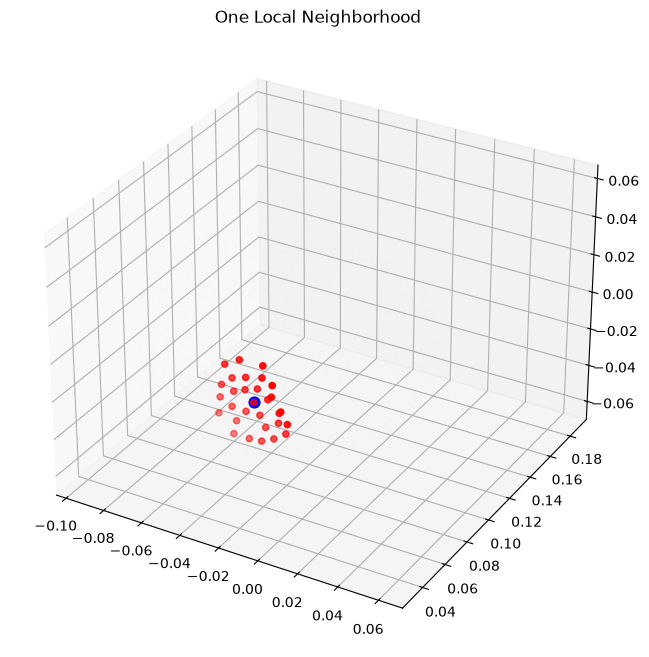

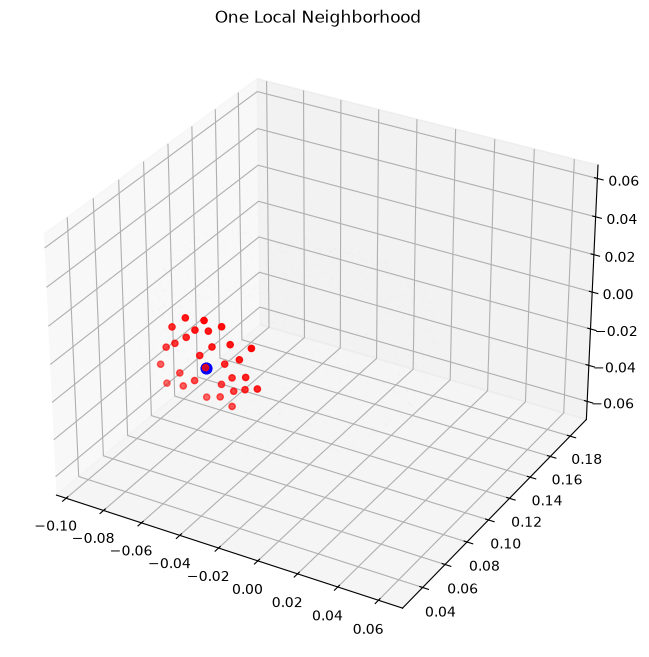

In [12]:
for i in range(num_samples):
    neigh = points[neighbor_indices[i]]
    fig = plt.figure(figsize=(8,8))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(
    points[:,0],
    points[:,1],
    points[:,2],
    s=1,
    alpha=.1
)
    ax.scatter(
    neigh[:,0],
    neigh[:,1],
    neigh[:,2],
    color='red',
    s=20
)
    ax.scatter(
    query_points[i,0],
    query_points[i,1],
    query_points[i,2],
    color='blue',
    s=60
)
    ax.set_title("One Local Neighborhood")
    plt.show()

In [13]:
# 3. Scatter Estimators
def tyler_m_estimator(X, tol=1e-6, max_iter=100):
    p = X.shape[1]
    mu = X.mean(axis=0)
    for _ in range(30):
        d = np.linalg.norm(X-mu,axis=1)
        d[d<1e-12]=1e-12
        w=1/d
        mu_new=(w[:,None]*X).sum(axis=0)/w.sum()
        if np.linalg.norm(mu_new-mu)<1e-9:
            mu=mu_new
            break 
        mu=mu_new

    Xc=X-mu

    Sigma=np.eye(p)

    for _ in range(max_iter):

        Sinv=np.linalg.inv(Sigma)

        quad=np.einsum(
            'ij,jk,ik->i',
            Xc,
            Sinv,
            Xc
        )

        quad[quad<1e-12]=1e-12

        Sigma_new=(p/len(Xc))*(
            Xc.T@(Xc/quad[:,None])
        )

        Sigma_new/=np.trace(Sigma_new)/p

        if np.linalg.norm(
            Sigma_new-Sigma
        )<tol:

            Sigma=Sigma_new
            break

        Sigma=Sigma_new

    return Sigma,mu


In [14]:
sigmas_list = []
means_list = []

for i, idx in enumerate(neighbor_indices):

    neighborhood = points[idx]

    print(
        f"Neighborhood {i}: "
        f"X shape = {neighborhood.shape}"
    )

    Sigma_i, mu_i = tyler_m_estimator(neighborhood)

    print(
        f"Sigma shape = {Sigma_i.shape}, "
        f"mu shape = {mu_i.shape}"
    )

    sigmas_list.append(Sigma_i)
    means_list.append(mu_i)

sigmas = np.stack(sigmas_list)
means = np.stack(means_list)

print("\nFinal:")
print("sigmas.shape:", sigmas.shape)
print("means.shape:", means.shape)

Neighborhood 0: X shape = (30, 3)
Sigma shape = (3, 3), mu shape = (3,)
Neighborhood 1: X shape = (30, 3)
Sigma shape = (3, 3), mu shape = (3,)
Neighborhood 2: X shape = (30, 3)
Sigma shape = (3, 3), mu shape = (3,)
Neighborhood 3: X shape = (30, 3)
Sigma shape = (3, 3), mu shape = (3,)
Neighborhood 4: X shape = (30, 3)
Sigma shape = (3, 3), mu shape = (3,)
Neighborhood 5: X shape = (30, 3)
Sigma shape = (3, 3), mu shape = (3,)
Neighborhood 6: X shape = (30, 3)
Sigma shape = (3, 3), mu shape = (3,)
Neighborhood 7: X shape = (30, 3)
Sigma shape = (3, 3), mu shape = (3,)
Neighborhood 8: X shape = (30, 3)
Sigma shape = (3, 3), mu shape = (3,)
Neighborhood 9: X shape = (30, 3)
Sigma shape = (3, 3), mu shape = (3,)
Neighborhood 10: X shape = (30, 3)
Sigma shape = (3, 3), mu shape = (3,)
Neighborhood 11: X shape = (30, 3)
Sigma shape = (3, 3), mu shape = (3,)
Neighborhood 12: X shape = (30, 3)
Sigma shape = (3, 3), mu shape = (3,)
Neighborhood 13: X shape = (30, 3)
Sigma shape = (3, 3), mu s

In [15]:
print("points.shape:", points.shape)
print("neighbor_indices.shape:", neighbor_indices.shape)

i = 0

idx = neighbor_indices[i]

print("idx.shape:", idx.shape)
print("points[idx].shape:", points[idx].shape)

points.shape: (1000, 3)
neighbor_indices.shape: (20, 30)
idx.shape: (30,)
points[idx].shape: (30, 3)


In [16]:
i = 0## Test 

# Keep one matrix as a batch
Sigma = sigmas[i:i+1]
print(Sigma)
print("Sigma shape:", Sigma.shape)

# Batched eigendecomposition
eigvals, eigvecs = np.linalg.eigh(Sigma)

print (eigvals)

print("eigvals shape before removing batch:", eigvals.shape)
print("eigvecs shape before removing batch:", eigvecs.shape)

# Remove the batch dimension
eigvals = eigvals[0]
eigvecs = eigvecs[0]

print("eigvals shape:", eigvals.shape)
print("eigvecs shape:", eigvecs.shape)

# Sort the 3 eigenvalues from largest to smallest
order = np.argsort(eigvals)[::-1]

eigvals = eigvals[order]
eigvecs = eigvecs[:, order]

# Local frame
e1 = eigvecs[:, 0]
e2 = eigvecs[:, 1]
n = eigvecs[:, 2]

print("\nSorted eigenvalues:")
print(eigvals)

print("\ne1:", e1)
print("e2:", e2)
print("n :", n)

# Keep one matrix as a batch
Sigma = sigmas[i:i+1]
print(Sigma)
print("Sigma shape:", Sigma.shape)

# Batched eigendecomposition
eigvals, eigvecs = np.linalg.eigh(Sigma)

print (eigvals)

print("eigvals shape before removing batch:", eigvals.shape)
print("eigvecs shape before removing batch:", eigvecs.shape)

# Remove the batch dimension
eigvals = eigvals[0]
eigvecs = eigvecs[0]

print("eigvals shape:", eigvals.shape)
print("eigvecs shape:", eigvecs.shape)

# Sort the 3 eigenvalues from largest to smallest
order = np.argsort(eigvals)[::-1]

eigvals = eigvals[order]
eigvecs = eigvecs[:, order]

# Local frame
e1 = eigvecs[:, 0]
e2 = eigvecs[:, 1]
n = eigvecs[:, 2]

print("\nSorted eigenvalues:")
print(eigvals)

print("\ne1:", e1)
print("e2:", e2)
print("n :", n)

[[[ 1.04180911  0.33447226  0.41721659]
  [ 0.33447226  1.06824384 -0.02740953]
  [ 0.41721659 -0.02740953  0.88994705]]]
Sigma shape: (1, 3, 3)
[[0.44363321 1.02561046 1.53075634]]
eigvals shape before removing batch: (1, 3)
eigvecs shape before removing batch: (1, 3, 3)
eigvals shape: (3,)
eigvecs shape: (3, 3)

Sorted eigenvalues:
[1.53075634 1.02561046 0.44363321]

e1: [-0.73371471 -0.50356243 -0.4561662 ]
e2: [ 0.14909525 -0.77432699  0.61497017]
n : [-0.66289768  0.38320045  0.64321387]
[[[ 1.04180911  0.33447226  0.41721659]
  [ 0.33447226  1.06824384 -0.02740953]
  [ 0.41721659 -0.02740953  0.88994705]]]
Sigma shape: (1, 3, 3)
[[0.44363321 1.02561046 1.53075634]]
eigvals shape before removing batch: (1, 3)
eigvecs shape before removing batch: (1, 3, 3)
eigvals shape: (3,)
eigvecs shape: (3, 3)

Sorted eigenvalues:
[1.53075634 1.02561046 0.44363321]

e1: [-0.73371471 -0.50356243 -0.4561662 ]
e2: [ 0.14909525 -0.77432699  0.61497017]
n : [-0.66289768  0.38320045  0.64321387]


In [17]:
##  Test : Plot local frame
i = 5

Sigma = sigmas[i]
center = means[i]

eigvals, eigvecs = np.linalg.eigh(Sigma)

order = eigvals.argsort()[::-1]

eigvals = eigvals[order]
eigvecs = eigvecs[:,order]

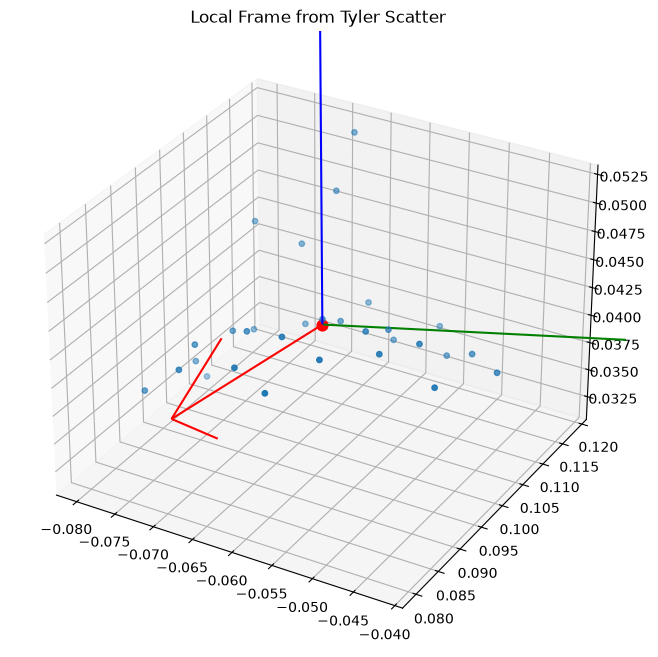

In [18]:
fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(111, projection='3d')

neigh = points[neighbor_indices[i]]

ax.scatter(
    neigh[:,0],
    neigh[:,1],
    neigh[:,2],
    s=15
)

ax.scatter(
    center[0],
    center[1],
    center[2],
    color='red',
    s=60
)

length = 0.05

colors = ['r','g','b']

for j in range(3):

    ax.quiver(
        center[0],
        center[1],
        center[2],
        eigvecs[0,j],
        eigvecs[1,j],
        eigvecs[2,j],
        length=length,
        color=colors[j]
    )

ax.set_title("Local Frame from Tyler Scatter")
plt.show()

In [19]:
# 4. Extract local frames 
# Store the local frames for all neighborhoods

tangent_1 = []
tangent_2 = []
normals = []
eigenvalues_all = []

for Sigma in sigmas:

    # eigh is appropriate because Sigma is symmetric
    eigvals, eigvecs = np.linalg.eigh(Sigma)

    # Sort from largest eigenvalue to smallest
    order = np.argsort(eigvals)[::-1]

    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]

    # For a locally planar surface:
    # e1, e2 = estimated tangent directions
    # n      = estimated normal direction
    e1 = eigvecs[:, 0]
    e2 = eigvecs[:, 1]
    n = eigvecs[:, 2]

    tangent_1.append(e1)
    tangent_2.append(e2)
    normals.append(n)
    eigenvalues_all.append(eigvals)

tangent_1 = np.asarray(tangent_1)
tangent_2 = np.asarray(tangent_2)
normals = np.asarray(normals)
eigenvalues_all = np.asarray(eigenvalues_all)

print("tangent_1 shape:", tangent_1.shape)
print("tangent_2 shape:", tangent_2.shape)
print("normals shape:", normals.shape)
print("eigenvalues shape:", eigenvalues_all.shape)

tangent_1 shape: (20, 3)
tangent_2 shape: (20, 3)
normals shape: (20, 3)
eigenvalues shape: (20, 3)


In [20]:
# Test
i = 0

print("Local center:")
print(means[i])

print("\nFirst tangent direction e1:")
print(tangent_1[i])

print("\nSecond tangent direction e2:")
print(tangent_2[i])

print("\nEstimated normal n:")
print(normals[i])

print("\nTyler shape eigenvalues:")
print(eigenvalues_all[i])

Local center:
[-0.05422121  0.04147356  0.03552438]

First tangent direction e1:
[-0.73371471 -0.50356243 -0.4561662 ]

Second tangent direction e2:
[ 0.14909525 -0.77432699  0.61497017]

Estimated normal n:
[-0.66289768  0.38320045  0.64321387]

Tyler shape eigenvalues:
[1.53075634 1.02561046 0.44363321]


In [21]:
# Project every neighborhood into local (u,v,w) coordinates
local_coordinates = []

for i, idx in enumerate(neighbor_indices):

    # Original 3D points in the neighborhood
    neighborhood = points[idx]

    # Local center and local frame
    center = means[i]
    e1 = tangent_1[i]
    e2 = tangent_2[i]
    n = normals[i]

    # Center the neighborhood
    centered_points = neighborhood - center

    # Project onto the local frame
    u = centered_points @ e1
    v = centered_points @ e2
    w = centered_points @ n

    # Each row is now [u, v, w]
    local_xyz = np.column_stack((u, v, w))

    local_coordinates.append(local_xyz)

local_coordinates = np.asarray(local_coordinates)

print("Local coordinate array shape:", local_coordinates.shape)

Local coordinate array shape: (20, 30, 3)


In [22]:
# Testing + Plot 
i = 0

local_xyz = local_coordinates[i]

print("First five local coordinates:")
print(local_xyz[:5])

First five local coordinates:
[[-2.85666470e-04  3.18100468e-03  9.31206495e-03]
 [ 3.91812313e-03 -1.75622789e-03  8.40377664e-03]
 [ 6.70653068e-05  1.04158599e-02  6.29911550e-03]
 [ 7.23120616e-03  5.38293200e-03  8.37631860e-03]
 [-2.79779376e-03 -3.78064053e-03  5.66021328e-03]]


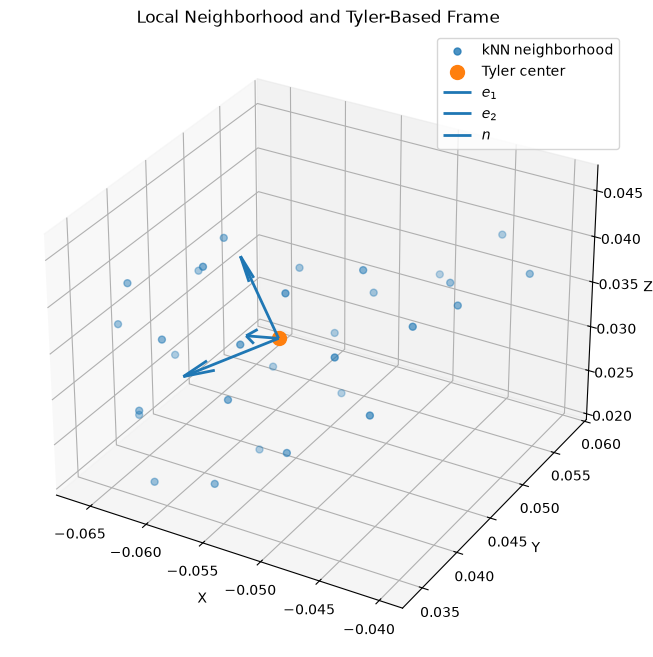

In [23]:

i = 0

neighborhood = points[neighbor_indices[i]]

center = means[i]
e1 = tangent_1[i]
e2 = tangent_2[i]
n = normals[i]

fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(111, projection="3d")

# Local neighborhood
ax.scatter(
    neighborhood[:, 0],
    neighborhood[:, 1],
    neighborhood[:, 2],
    s=25,
    alpha=0.8,
    label="kNN neighborhood"
)

# Robust local center
ax.scatter(
    center[0],
    center[1],
    center[2],
    s=100,
    marker="o",
    label="Tyler center"
)

# Frame size based on the neighborhood diameter
frame_length = 0.4 * np.max(
    np.linalg.norm(neighborhood - center, axis=1)
)

# Local frame vectors
ax.quiver(
    center[0], center[1], center[2],
    e1[0], e1[1], e1[2],
    length=frame_length,
    linewidth=2,
    label="$e_1$"
)

ax.quiver(
    center[0], center[1], center[2],
    e2[0], e2[1], e2[2],
    length=frame_length,
    linewidth=2,
    label="$e_2$"
)

ax.quiver(
    center[0], center[1], center[2],
    n[0], n[1], n[2],
    length=frame_length,
    linewidth=2,
    label="$n$"
)

ax.set_title("Local Neighborhood and Tyler-Based Frame")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.legend()

plt.show()

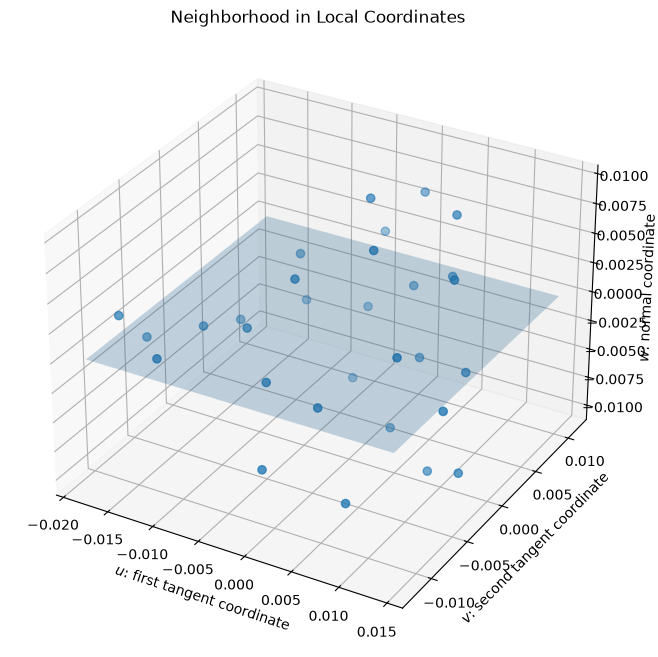

In [24]:
# Test Plot Tangent Plane 
i = 0

local_xyz = local_coordinates[i]

u = local_xyz[:, 0]
v = local_xyz[:, 1]
w = local_xyz[:, 2]

fig = plt.figure(figsize=(9, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    u,
    v,
    w,
    s=35,
    alpha=0.9
)

# Add the local tangent plane w = 0
U, V = np.meshgrid(
    np.linspace(u.min(), u.max(), 20),
    np.linspace(v.min(), v.max(), 20)
)

W = np.zeros_like(U)

ax.plot_surface(
    U,
    V,
    W,
    alpha=0.25
)

ax.set_title("Neighborhood in Local Coordinates")
ax.set_xlabel("$u$: first tangent coordinate")
ax.set_ylabel("$v$: second tangent coordinate")
ax.set_zlabel("$w$: normal coordinate")

plt.show()

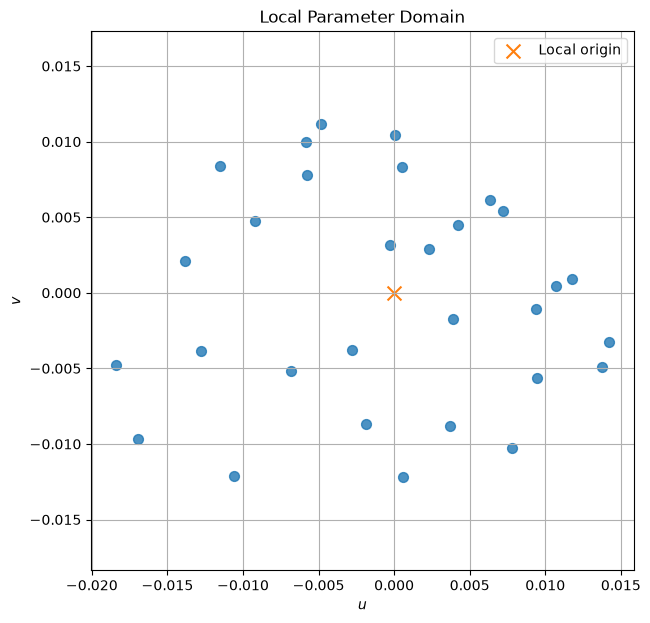

In [25]:
# Test Plot : show the points on Tangent plane 
i = 0

local_xyz = local_coordinates[i]

u = local_xyz[:, 0]
v = local_xyz[:, 1]

plt.figure(figsize=(7, 7))

plt.scatter(
    u,
    v,
    s=50,
    alpha=0.8
)

plt.scatter(
    0,
    0,
    s=100,
    marker="x",
    label="Local origin"
)

plt.xlabel("$u$")
plt.ylabel("$v$")
plt.title("Local Parameter Domain")
plt.axis("equal")
plt.grid(True)
plt.legend()

plt.show()

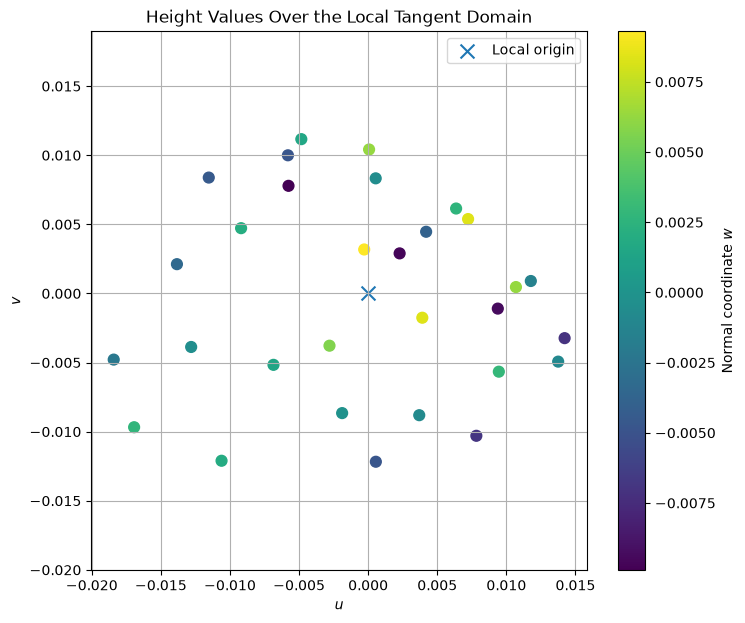

In [26]:
# Test Plot : Visualize height w
i = 0

local_xyz = local_coordinates[i]

u = local_xyz[:, 0]
v = local_xyz[:, 1]
w = local_xyz[:, 2]

plt.figure(figsize=(8, 7))

scatter = plt.scatter(
    u,
    v,
    c=w,
    s=60
)

plt.colorbar(scatter, label="Normal coordinate $w$")

plt.scatter(
    0,
    0,
    s=100,
    marker="x",
    label="Local origin"
)

plt.xlabel("$u$")
plt.ylabel("$v$")
plt.title("Height Values Over the Local Tangent Domain")
plt.axis("equal")
plt.grid(True)
plt.legend()

plt.show()

In [27]:
# Test Checking the local parametrization error 
i = 0

local_xyz = local_coordinates[i]

u = local_xyz[:, 0]
v = local_xyz[:, 1]
w = local_xyz[:, 2]

center = means[i]
e1 = tangent_1[i]
e2 = tangent_2[i]
n = normals[i]

reconstructed_points = (
    center
    + u[:, None] * e1
    + v[:, None] * e2
    + w[:, None] * n
)

original_neighborhood = points[neighbor_indices[i]]

reconstruction_error = np.linalg.norm(
    reconstructed_points - original_neighborhood,
    axis=1
)

print(
    "Maximum coordinate reconstruction error:",
    reconstruction_error.max()
)

print(
    "Mean coordinate reconstruction error:",
    reconstruction_error.mean()
)

Maximum coordinate reconstruction error: 1.5899003276961254e-17
Mean coordinate reconstruction error: 8.648277500777997e-18


In [28]:
# Checking the shapes and range of coordinates
i = 0

local_xyz = local_coordinates[i]

u = local_xyz[:, 0]
v = local_xyz[:, 1]
w = local_xyz[:, 2]

print("u shape:", u.shape)
print("v shape:", v.shape)
print("w shape:", w.shape)

print("u range:", u.min(), u.max())
print("v range:", v.min(), v.max())
print("w range:", w.min(), w.max())

u shape: (30,)
v shape: (30,)
w shape: (30,)
u range: -0.018410490690757703 0.014215351291373902
v range: -0.012176804833507415 0.011164157195427812
w range: -0.009885165744382916 0.009312064950264902


In [29]:
# Mapping the directional vector s,t for berstein polynomial basis

u_min = u.min()
u_max = u.max()

v_min = v.min()
v_max = v.max()

# Avoid division by zero
u_range = max(u_max - u_min, 1e-12)
v_range = max(v_max - v_min, 1e-12)

# Normalized Bézier parameters
s = (u - u_min) / u_range
t = (v - v_min) / v_range

print("s range:", s.min(), s.max())
print("t range:", t.min(), t.max())


# Tranform to Bezier surface (s,t,w)

s range: 0.0 1.0
t range: 0.0 1.0


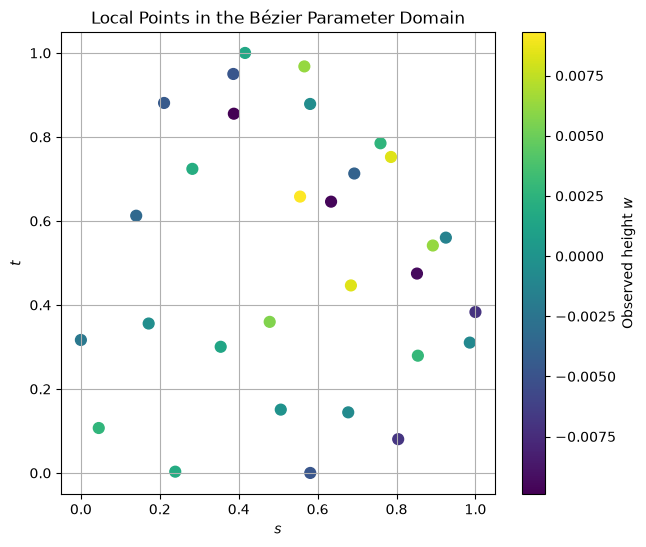

In [30]:
plt.figure(figsize=(7, 6))

plt.scatter(
    s,
    t,
    c=w,
    s=60
)

plt.colorbar(label="Observed height $w$")

plt.xlabel("$s$")
plt.ylabel("$t$")

plt.title("Local Points in the Bézier Parameter Domain")

plt.xlim(-0.05, 1.05)
plt.ylim(-0.05, 1.05)

plt.grid(True)

plt.show()

### Construct of the Bezier surface 


Define basis 
|
|
v
Calculate the tensor product( points location on the surface) = matrix shape + control height 
|
|
V

In [31]:
# Define Berstein basis B^d(s) of degree d
from math import comb

def bernstein_basis(x, degree):
    """
    Compute all Bernstein basis functions of a given degree.

    Parameters
    ----------
    x : array
        Parameter values in [0, 1].

    degree : int
        Bézier degree.

    Returns
    -------
    B : array, shape (len(x), degree + 1)
    """

    x = np.asarray(x)

    B = np.zeros(
        (len(x), degree + 1)
    )

    for a in range(degree + 1):

        B[:, a] = (
            comb(degree, a)
            * x**a
            * (1 - x)**(degree - a)
        )

    return B

#### d=2

In [40]:
# Construct bezier surface of degree 2. Calculate the 3d coordinate h() on the surface 
degree = 2
def ber_shape_matrix(s,t,degree):
    Bs = bernstein_basis(s, degree)
    Bt = bernstein_basis(t, degree)
    num_points = len(s)
    num_control = (degree + 1)**2
    A = np.zeros(
    (num_points, num_control)
)
    column = 0
    for a in range(degree + 1):
        for b in range(degree + 1):
            A[:, column] = (
            Bs[:, a]
            * Bt[:, b]
        )
            column += 1
    print("Design matrix shape:", A.shape)
    return A 

A1= ber_shape_matrix(s,t,degree)


Design matrix shape: (30, 9)


In [61]:
# Fit Bezier high = minimize the residual of || AP- w||^2
def control_h_matrix (A,w):
    control_vector, residuals, rank, singular_values = (
    np.linalg.lstsq(
        A,
        w,
        rcond=None
    )
)

# Convert the vector into a control grid
    control_heights = control_vector.reshape(
    degree + 1,
    degree + 1
)
    print("Control-height matrix:")
    print(control_heights)
    print("\nMatrix rank:", rank)
    return control_heights, control_vector
control_heights, control_vector= control_h_matrix(A1, w)

Control-height matrix:
[[ 0.00592375 -0.0083972  -0.00910726]
 [-0.00435183  0.0191583  -0.00374009]
 [-0.00480669 -0.00834699  0.01223175]]

Matrix rank: 9


In [57]:
w_fitted = A1 @ control_vector

rmse = np.sqrt(
    np.mean(
        (w - w_fitted)**2
    )
)

print("Bézier height RMSE:", rmse)

Bézier height RMSE: 0.004732733043676777


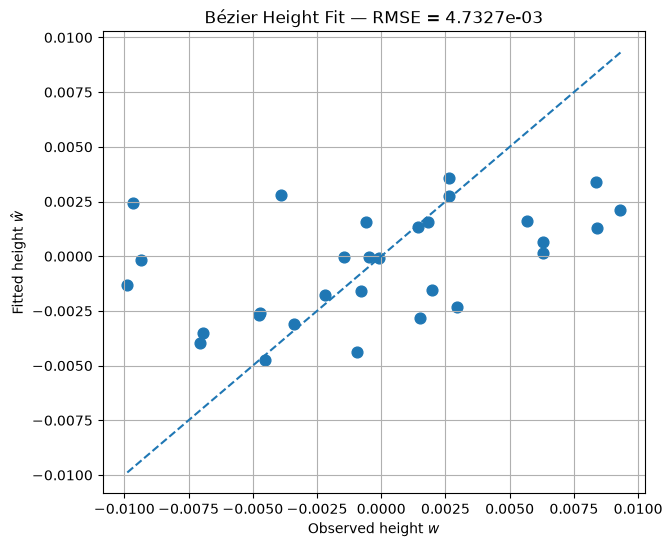

In [35]:
# Compare the observe height w vs fitted height AP

plt.figure(figsize=(7, 6))

plt.scatter(
    w,
    w_fitted,
    s=60
)

min_height = min(
    w.min(),
    w_fitted.min()
)

max_height = max(
    w.max(),
    w_fitted.max()
)

plt.plot(
    [min_height, max_height],
    [min_height, max_height],
    linestyle="--"
)

plt.xlabel("Observed height $w$")
plt.ylabel("Fitted height $\\hat w$")

plt.title(
    f"Bézier Height Fit — RMSE = {rmse:.4e}"
)

plt.grid(True)

plt.show()

#If the fit is good, the points should lie close to the diagonal.

### Comparing the different d

In [76]:
from math import comb

def bernstein_basis(x, degree):
    x = np.asarray(x)
    B = np.zeros(
        (len(x), degree + 1))
    for a in range(degree + 1):
        B[:, a] = (
            comb(degree, a)
            * x**a
            * (1 - x)**(degree - a)
        )

    return B


def fit_bezier_height(s, t, w, degree):
    Bs = bernstein_basis(s,degree)
    Bt = bernstein_basis( t, degree)
    n_points = len(s)
    n_control = (degree + 1)**2
    A = np.zeros(
        (
            n_points,
            n_control
        )
    )

    column = 0

    for a in range(degree + 1):

        for b in range(degree + 1):

            A[:, column] = (
                Bs[:, a]
                * Bt[:, b]
            )

            column += 1

    control_vector, _, rank, singular_values = (
        np.linalg.lstsq(A,w,rcond=None)
    )

    w_fitted = ( A@ control_vector)
    rmse = np.sqrt(
        np.mean(
            (w-w_fitted)**2
        )
    )

    nrmse = (
        rmse
        / max(
            np.std(w),
            1e-12
        )
    )

    return  degree, control_vector, w_fitted, rmse,nrmse,rank,A



In [65]:
results = []

for degree in [1, 2, 3]:

    result = fit_bezier_height(
        s,
        t,
        w,
        degree
    )

    results.append(result)

    print(
        f"Degree {degree}: "
        f"RMSE = {result['rmse']:.6e}, "
        f"NRMSE = {result['nrmse']:.4f}, "
        f"rank = {result['rank']}"
    )

Degree 1: RMSE = 4.904508e-03, NRMSE = 0.9234, rank = 4
Degree 2: RMSE = 4.732733e-03, NRMSE = 0.8911, rank = 9
Degree 3: RMSE = 4.097292e-03, NRMSE = 0.7714, rank = 16


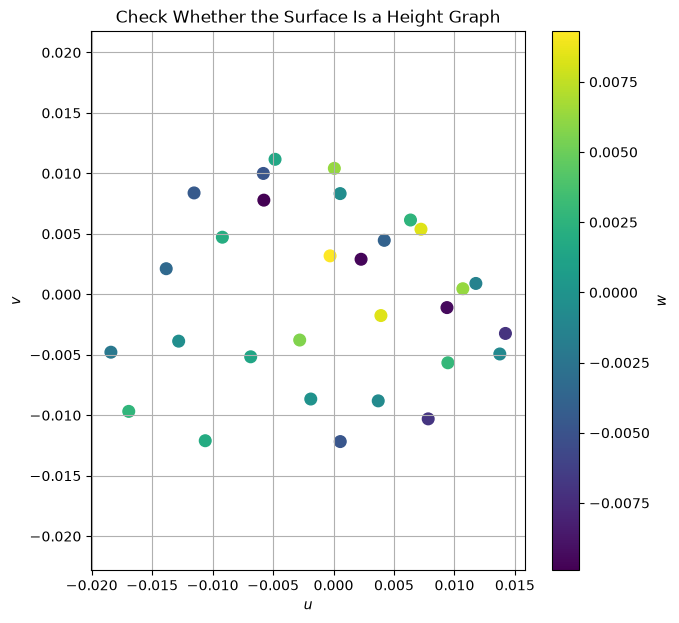

In [66]:
plt.figure(figsize=(7, 7))

plt.scatter(
    u,
    v,
    c=w,
    s=70
)

plt.colorbar(
    label="$w$"
)

plt.xlabel("$u$")
plt.ylabel("$v$")

plt.title(
    "Check Whether the Surface Is a Height Graph"
)

plt.axis("equal")

plt.grid(True)

plt.show()

 Conclusion, d=3 for the best fit 

In [77]:
degree, control_vector, w_fitted,rmse, nrmse, rank , A= fit_bezier_height(s,t,w,degree=3)

In [79]:
# Convert the Bézier parameters back to local coordinates
U_grid = (
    u_min
    + S * u_range
)

V_grid = (
    v_min
    + T * v_range
)


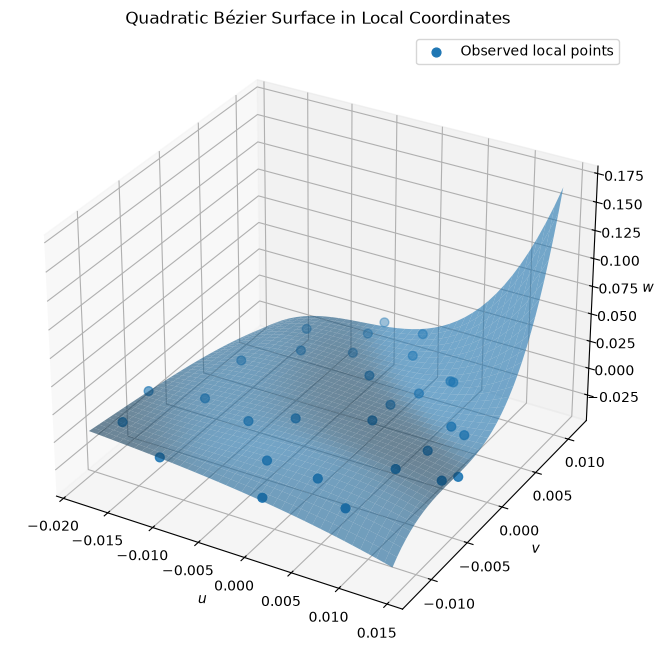

In [80]:
# Fit bezier surface on local coordinate

fig = plt.figure(
    figsize=(10, 8)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

# Observed local points
ax.scatter(
    u,
    v,
    w,
    s=40,
    label="Observed local points"
)

# Fitted Bézier height surface
ax.plot_surface(
    U_grid,
    V_grid,
    W_fit,
    alpha=0.6
)

ax.set_xlabel("$u$")
ax.set_ylabel("$v$")
ax.set_zlabel("$w$")

ax.set_title(
    "Quadratic Bézier Surface in Local Coordinates"
)

ax.legend()

plt.show()

In [81]:
# Map the Bezier back to local coordinate 
i = 0

center = means[i]

e1 = tangent_1[i]
e2 = tangent_2[i]
n = normals[i]

global_surface = (
    center[None, None, :]
    + U_grid[:, :, None]
      * e1[None, None, :]
    + V_grid[:, :, None]
      * e2[None, None, :]
    + W_fit[:, :, None]
      * n[None, None, :]
)

X_fit = global_surface[:, :, 0]
Y_fit = global_surface[:, :, 1]
Z_fit = global_surface[:, :, 2]

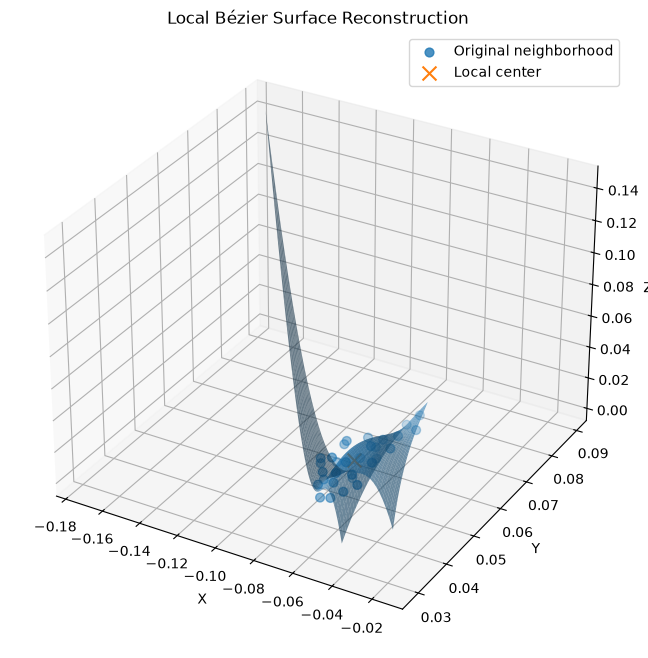

In [85]:
# plot Bezier patch on global coordinate 
i = 0

neighborhood = points[
    neighbor_indices[i]
]

fig = plt.figure(
    figsize=(8, 8)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

# Original neighborhood
ax.scatter(
    neighborhood[:, 0],
    neighborhood[:, 1],
    neighborhood[:, 2],
    s=40,
    alpha=0.8,
    label="Original neighborhood"
)

# Reconstructed Bézier patch
ax.plot_surface(
    X_fit,
    Y_fit,
    Z_fit,
    alpha=0.6
)

# Local center
ax.scatter(
    center[0],
    center[1],
    center[2],
    s=100,
    marker="x",
    label="Local center"
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

ax.set_title(
    "Local Bézier Surface Reconstruction"
)

ax.legend()

plt.show()

### Final pipeline




Real point cloud neighborhood
             │
             ▼

Robust scatter matrix Σ
             │
             ▼

Local frame (e₁, e₂, n)
             │
             ▼

Tangent plane spanned by e₁ and e₂
             │
             ▼

Real point xⱼ → local coordinates (uⱼ, vⱼ, wⱼ)
             │
             ▼

(uⱼ, vⱼ) = Bézier parameter location
wⱼ = observed height
             │
             ▼

Fit Bézier height function h(u,v)
             │
             ▼

Local Bézier patch:
(u, v, h(u,v))
             │
             ▼

Map back:
X̂ = c + u e₁ + v e₂ + h(u,v)n
             │
             ▼
             
Reconstructed local surface in ℝ³

### Final pipeline with Probing 




Real point cloud neighborhood
             │
             ▼

Robust scatter matrix Σ
             │
             ▼

Local frame (e₁, e₂, n)
             │
             ▼

Tangent plane spanned by e₁ and e₂
             │
             ▼

Define the local pattern point p_i = e1. u_i + e2. v_i + s

Define the local probing operator P(p_i)

Find the displacement = P(p_i)- p_i 

Mapping the estimate height function to find the control bezier point 

Real point xⱼ → local coordinates (uⱼ, vⱼ, wⱼ)
             │
             ▼

(uⱼ, vⱼ) = Bézier parameter location
wⱼ = observed height
             │
             ▼

Fit Bézier height function h(u,v)
             │
             ▼

Local Bézier patch:
(u, v, h(u,v))
             │
             ▼

Map back:
X̂ = c + u e₁ + v e₂ + h(u,v)n
             │
             ▼
             
Reconstructed local surface in ℝ³